In [ ]:
import pandas as pd
import os
from google.colab import drive

# 1. Mount Drive first so we can reach the folder
print("Mounting Google Drive...")
drive.mount('/content/drive')

# 2. Point directly to your permanent Drive folder
DRIVE_DIR = "/content/drive/MyDrive/Detection_thesis"
csv_path = os.path.join(DRIVE_DIR, "shuffled_dataset.csv")
output_path = os.path.join(DRIVE_DIR, "dataset.jsonl")

# 3. Process the file
df = pd.read_csv(csv_path)
print("Original Columns:", df.columns)
print(df.head(2))

df = df.rename(columns={
    'poem': 'text',
    'author_type': 'label'
})
df['label'] = df['label'].map({'Human': 0, 'AI': 1})

df_clean = df[['text', 'label']]

# 4. Save the JSONL directly into your Drive
df_clean.to_json(output_path, orient='records', lines=True, force_ascii=False)

print(f"\nSuccess! Dataset successfully converted and saved directly to Drive: {output_path}")

Mounting Google Drive...
Mounted at /content/drive
Original Columns: Index(['poem', 'source', 'author_type'], dtype='object')
                                                poem      source author_type
0  The Lighthouse in the Storm \n\nThe storm had ...  qwen-3-32b          AI
1  The Garden's Secret\nThe garden breathes in mo...  qwen-3-32b          AI

Success! Dataset successfully converted and saved directly to Drive: /content/drive/MyDrive/Detection_thesis/dataset.jsonl


In [ ]:
!pip install -q transformers accelerate bitsandbytes pandas tqdm datasets

In [ ]:
import os
import gc
import torch
import numpy as np
import pandas as pd
from tqdm import tqdm
from google.colab import drive
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

# ==========================================
# 0. GOOGLE DRIVE SETUP (CRASH-PROOFING)
# ==========================================
print("Mounting Google Drive...")
drive.mount('/content/drive')

# Define the master directory in your Google Drive
DRIVE_DIR = "/content/drive/MyDrive/Detection_thesis"
os.makedirs(DRIVE_DIR, exist_ok=True)

# 1. Device Setup
dtype = torch.float16
quant_config = BitsAndBytesConfig(load_in_8bit=True)

# 2. Clean Data Loader (Paths updated to Google Drive)
pass2_checkpoint = os.path.join(DRIVE_DIR, "pass2_checkpoint.jsonl")
pass1_complete = os.path.join(DRIVE_DIR, "pass1_complete.jsonl")
pass1_checkpoint = os.path.join(DRIVE_DIR, "pass1_checkpoint.jsonl")
original_dataset = os.path.join(DRIVE_DIR, "dataset.jsonl")

print("Checking for existing datasets and backups...")
if os.path.exists(pass2_checkpoint):
    print("Found Pass 2 checkpoint! Loading...")
    df = pd.read_json(pass2_checkpoint, lines=True)
elif os.path.exists(pass1_complete):
    print("Found completed Pass 1! Loading...")
    df = pd.read_json(pass1_complete, lines=True)
elif os.path.exists(pass1_checkpoint):
    print("Found Pass 1 checkpoint! Loading...")
    df = pd.read_json(pass1_checkpoint, lines=True)
elif os.path.exists(original_dataset):
    print("No backups found. Starting fresh from original dataset...")
    df = pd.read_json(original_dataset, lines=True)
    df = df[df["text"].str.strip().str.len() >= 10]
else:
    raise FileNotFoundError(f"Could not find ANY dataset files! Make sure 'dataset.jsonl' is in {DRIVE_DIR}")

data_records = df.to_dict('records')
print(f"Total valid records loaded: {len(data_records)}")
print(f"Total valid records to process: {len(data_records)}")

# ==========================================
# PASS 1: QWEN 2.5 3B (Base Metrics & Perturbations)
# ==========================================
print("\n--- STARTING PASS 1 ---")
print("Loading Qwen2.5-3B (Scoring/Reference Model) in Pure BF16...")
tokenizer_3b = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B")
model_3b = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-3B",
    torch_dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="sdpa" # Native PyTorch Flash Attention!
)

def calculate_base_metrics(text, model, tokenizer):
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model(**inputs, labels=inputs["input_ids"])
        logits = outputs.logits

    loss_fct = torch.nn.CrossEntropyLoss(reduction="none")
    shift_logits = logits[..., :-1, :].contiguous()
    shift_labels = inputs["input_ids"][..., 1:].contiguous()

    losses = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))
    log_likelihood = -losses.mean().item()

    probs = torch.softmax(shift_logits, dim=-1)
    ranks = []
    for i in range(shift_labels.size(1)):
        true_token_id = shift_labels[0, i].item()
        sorted_probs, sorted_indices = torch.sort(probs[0, i], descending=True)
        rank = (sorted_indices == true_token_id).nonzero(as_tuple=True)[0].item() + 1
        ranks.append(rank)

    log_ranks = np.log(ranks)
    mean_log_rank = np.mean(log_ranks)
    lrr = log_likelihood / mean_log_rank
    return log_likelihood, mean_log_rank, lrr

def generate_perturbations(text, model, tokenizer, num_perturbations=5):
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    perturbed_samples = []
    for _ in range(num_perturbations):
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=20,
                do_sample=True,
                temperature=1.0,
                top_p=0.95,
                pad_token_id=tokenizer.eos_token_id,
                use_cache=True  # <--- ADD THIS LINE
            )
        perturbed_samples.append(tokenizer.decode(outputs[0], skip_special_tokens=True))
    return perturbed_samples

# CHUNKING CONFIGURATION
MAX_TEXTS_PER_SESSION = 10000
texts_processed_today = 0
hit_chunk_limit = False

# Run Pass 1
for i, record in enumerate(tqdm(data_records, desc="Pass 1 (3B Metrics)")):
    if pd.notna(record.get("score_log_likelihood")):
        continue

    try:
        text = record["text"]
        ll, log_rank, lrr = calculate_base_metrics(text, model_3b, tokenizer_3b)
        record["score_log_likelihood"] = ll
        record["score_log_rank"] = log_rank
        record["score_lrr"] = lrr
        record["perturbed_samples"] = generate_perturbations(text, model_3b, tokenizer_3b)
        texts_processed_today += 1
    except Exception as e:
        print(f"Error in Pass 1 for text: {e}")
        record["error"] = True
        texts_processed_today += 1

    # AUTO-SAVE CHECKPOINT EVERY 50 ROWS (Directly to Drive)
    if texts_processed_today % 50 == 0 and texts_processed_today > 0:
        backup_df = pd.DataFrame(data_records)
        backup_df.to_json(pass1_checkpoint, orient="records", lines=True)

    # SESSION BRAKE: Stop automatically when chunk is completed
    if texts_processed_today >= MAX_TEXTS_PER_SESSION:
        print(f"\n[SUCCESS] Reached safe chunk limit of {MAX_TEXTS_PER_SESSION} texts!")
        hit_chunk_limit = True
        break

# If we stopped early due to the chunk limit, save safely and exit before Pass 2
if hit_chunk_limit:
    safe_save_name = os.path.join(DRIVE_DIR, f"pass1_safe_save_row_{i}.jsonl")
    pd.DataFrame(data_records).to_json(safe_save_name, orient="records", lines=True)
    pd.DataFrame(data_records).to_json(pass1_checkpoint, orient="records", lines=True)

    print("\n" + "="*50)
    print(f"🛑 STOP! PASS 1 IS PAUSED FOR THIS SESSION. 🛑")
    print(f"Everything is securely saved in your Google Drive ({DRIVE_DIR}).")
    print(f"You can safely close Colab now and resume later!")
    print("="*50)

    import sys
    sys.exit("Stopping script cleanly. Your chunk backup is in Google Drive.")

# If we made it here without hitting the limit, Pass 1 is completely finished!
pd.DataFrame(data_records).to_json(pass1_complete, orient="records", lines=True)

# ==========================================
# MEMORY CLEARING PHASE
# ==========================================
print("\nCleaning up GPU Memory before Pass 2...")
del model_3b
del tokenizer_3b
gc.collect()
torch.cuda.empty_cache()

# ==========================================
# PASS 2: QWEN 2.5 7B (Binoculars & FastDetectGPT Scoring)
# ==========================================
print("\n--- STARTING PASS 2 ---")
print("Loading Qwen2.5-7B (Scoring/Observer Model)...")
tokenizer_7b = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-7B")
model_7b = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-7B",
    dtype=dtype,
    quantization_config=quant_config,
    device_map="auto"
)

print("Loading Qwen2.5-7B-Instruct (Performer Model for Binoculars)...")
model_7b_inst = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-7B-Instruct",
    dtype=dtype,
    quantization_config=quant_config,
    device_map="auto"
)

def calculate_binoculars(text, model_obs, model_perf, tokenizer):
    inputs = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        logits_obs = model_obs(**inputs.to(model_obs.device)).logits[..., :-1, :]
        logits_perf = model_perf(**inputs.to(model_perf.device)).logits[..., :-1, :]

    labels = inputs["input_ids"][..., 1:]
    loss_fct = torch.nn.CrossEntropyLoss(reduction="none")

    losses_perf = loss_fct(logits_perf.cpu().view(-1, logits_perf.size(-1)), labels.cpu().view(-1))
    h_q_q = losses_perf.mean().item()

    losses_cross = loss_fct(logits_obs.cpu().view(-1, logits_obs.size(-1)), labels.cpu().view(-1))
    h_p_q = losses_cross.mean().item()

    return h_p_q / h_q_q

def score_fast_detect_gpt(text, perturbed_samples, model_scorer, tokenizer):
    def get_likelihood(t):
        inp = tokenizer(t, return_tensors="pt")
        with torch.no_grad():
            out = model_scorer(**inp.to(model_scorer.device), labels=inp["input_ids"].to(model_scorer.device))
        return -out.loss.item()

    orig_likelihood = get_likelihood(text)
    perturbed_likelihoods = [get_likelihood(p) for p in perturbed_samples]

    mean_pert = np.mean(perturbed_likelihoods)
    std_pert = np.std(perturbed_likelihoods) if np.std(perturbed_likelihoods) > 0 else 1.0

    return (orig_likelihood - mean_pert) / std_pert

# Run Pass 2
for i, record in enumerate(tqdm(data_records, desc="Pass 2 (7B Metrics)")):
    if record.get("error"):
        continue

    if pd.notna(record.get("score_binoculars")):
        continue

    try:
        text = record["text"]
        perturbed_samples = record.get("perturbed_samples", [])

        record["score_binoculars"] = calculate_binoculars(text, model_7b, model_7b_inst, tokenizer_7b)
        record["score_fast_detect"] = score_fast_detect_gpt(text, perturbed_samples, model_7b, tokenizer_7b)
        record.pop("perturbed_samples", None)

    except Exception as e:
        print(f"Error in Pass 2 for text: {e}")
        record["error"] = True

    # AUTO-SAVE CHECKPOINT EVERY 50 ROWS (Directly to Drive)
    if (i + 1) % 50 == 0:
        backup_df = pd.DataFrame(data_records)
        backup_df.to_json(pass2_checkpoint, orient="records", lines=True)

# ==========================================
# FINAL OUTPUT
# ==========================================
final_results = [r for r in data_records if not r.get("error")]
output_df = pd.DataFrame(final_results)

output_csv = os.path.join(DRIVE_DIR, "detector_scores.csv")
output_jsonl = os.path.join(DRIVE_DIR, "pass2_complete.jsonl")

output_df.to_csv(output_csv, index=False)
output_df.to_json(output_jsonl, orient="records", lines=True)

print(f"\nFinished batch processing! Scores successfully saved to {output_csv}")

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checking for existing datasets and backups...
Found Pass 1 checkpoint! Loading...
Total valid records loaded: 5970
Total valid records to process: 5970

--- STARTING PASS 1 ---
Loading Qwen2.5-3B (Scoring/Reference Model) in Pure BF16...


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Pass 1 (3B Metrics): 100%|██████████| 5970/5970 [2:06:09<00:00,  1.27s/it]



Cleaning up GPU Memory before Pass 2...

--- STARTING PASS 2 ---
Loading Qwen2.5-7B (Scoring/Observer Model)...


config.json:   0%|          | 0.00/686 [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Streaming output truncated to the last 5000 lines.
Pass 2 (7B Metrics): 100%|██████████| 5970/5970 [3:07:58<00:00,  1.89s/it]



Finished batch processing! Scores successfully saved to /content/drive/MyDrive/Detection_thesis/detector_scores.csv


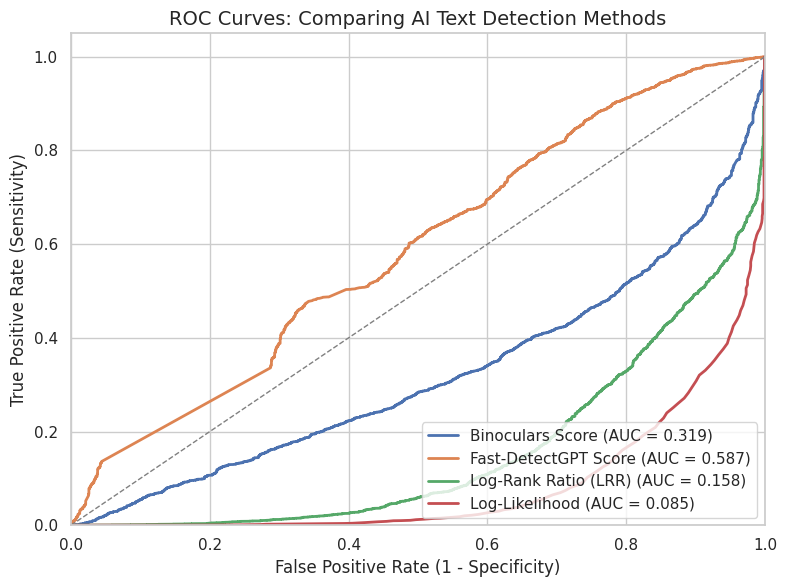

Saved ROC Curve comparison to: /content/drive/MyDrive/Detection_thesis/roc_curves_comparison.png


/tmp/ipykernel_6870/1202631917.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_6870/1202631917.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


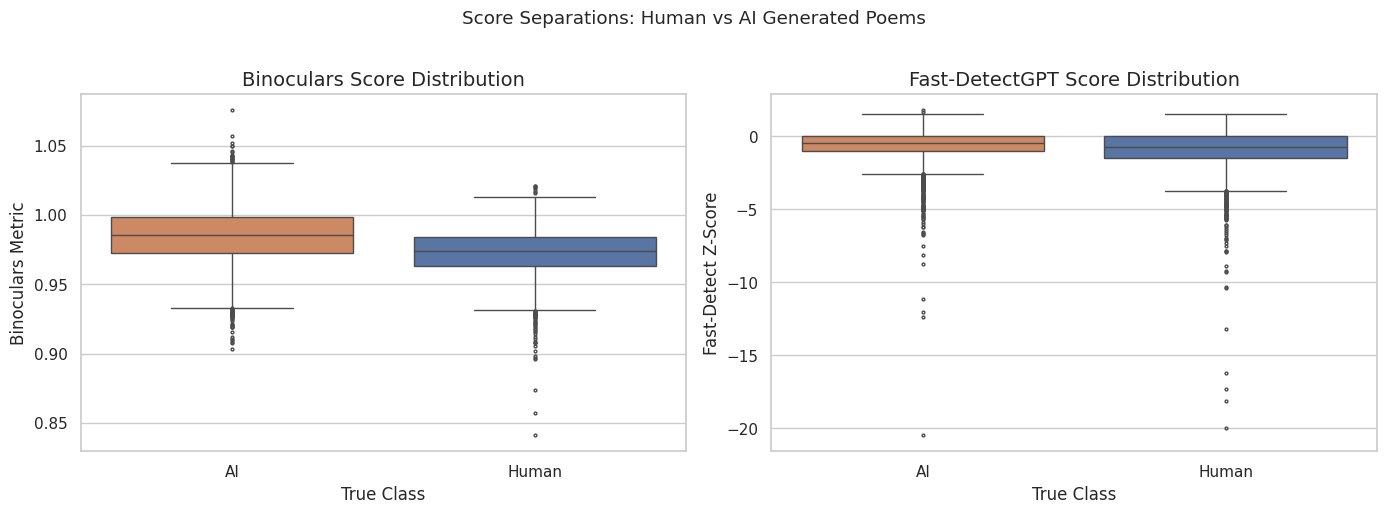

Saved Score Distributions to: /content/drive/MyDrive/Detection_thesis/score_distributions.png


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# 1. Load your completed results from Google Drive
DRIVE_DIR = "/content/drive/MyDrive/Detection_thesis"
csv_path = os.path.join(DRIVE_DIR, "detector_scores.csv")

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Could not find {csv_path}. Wait for the main run to completely finish!")

df = pd.read_csv(csv_path)

# Map numeric labels back to strings for cleaner plot legends
df['Author Type'] = df['label'].map({0: 'Human', 1: 'AI'})

# List of metrics we want to analyze
metrics = {
    'score_binoculars': 'Binoculars Score',
    'score_fast_detect': 'Fast-DetectGPT Score',
    'score_lrr': 'Log-Rank Ratio (LRR)',
    'score_log_likelihood': 'Log-Likelihood'
}

# Set up style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})

# =========================================================
# PLOT 1: ROC CURVES (Classification Performance Comparison)
# =========================================================
plt.figure(figsize=(8, 6))

for metric_col, title in metrics.items():
    # Drop NaNs just in case an error occurred on a specific row
    clean_df = df[[metric_col, 'label']].dropna()

    y_true = clean_df['label']
    y_scores = clean_df[metric_col]

    # Note: For some metrics like Binoculars, lower scores mean AI text.
    # We check if the correlation is negative and invert scores for proper ROC calculation if necessary.
    if metric_col in ['score_binoculars', 'score_log_likelihood']:
        y_scores = -y_scores  # Invert so higher score = higher probability of being AI (1)

    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, lw=2, label=f'{title} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves: Comparing AI Text Detection Methods')
plt.legend(loc="lower right")
plt.tight_layout()

# Save plot to your Drive
roc_save_path = os.path.join(DRIVE_DIR, "roc_curves_comparison.png")
plt.savefig(roc_save_path, dpi=300)
plt.show()
print(f"Saved ROC Curve comparison to: {roc_save_path}")


# =========================================================
# PLOT 2: DISTRIBUTION BOXPLOTS (Human vs AI Separation)
# =========================================================
# We will plot boxplots for your top two advanced metrics: Binoculars and Fast-DetectGPT
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot for Binoculars
sns.boxplot(
    data=df,
    x='Author Type',
    y='score_binoculars',
    ax=axes[0],
    palette={'Human': '#4C72B0', 'AI': '#DD8452'},
    fliersize=2
)
axes[0].set_title('Binoculars Score Distribution')
axes[0].set_xlabel('True Class')
axes[0].set_ylabel('Binoculars Metric')

# Boxplot for Fast-DetectGPT
sns.boxplot(
    data=df,
    x='Author Type',
    y='score_fast_detect',
    ax=axes[1],
    palette={'Human': '#4C72B0', 'AI': '#DD8452'},
    fliersize=2
)
axes[1].set_title('Fast-DetectGPT Score Distribution')
axes[1].set_xlabel('True Class')
axes[1].set_ylabel('Fast-Detect Z-Score')

plt.suptitle('Score Separations: Human vs AI Generated Poems', y=1.02)
plt.tight_layout()

# Save plot to your Drive
dist_save_path = os.path.join(DRIVE_DIR, "score_distributions.png")
plt.savefig(dist_save_path, dpi=300)
plt.show()
print(f"Saved Score Distributions to: {dist_save_path}")

🏆 TRUE BALANCED THRESHOLDS (Auto-Corrected) 🏆
--------------------------------------------------
Log-Likelihood:
  -> True AUC: 0.915 (Inverted: False)
  -> Realistic F1 Score: 0.909
  -> Optimal Threshold: -3.141

Log-Rank Ratio:
  -> True AUC: 0.842 (Inverted: True)
  -> Realistic F1 Score: 0.862
  -> Optimal Threshold: -1.901

Binoculars Score:
  -> True AUC: 0.681 (Inverted: False)
  -> Realistic F1 Score: 0.652
  -> Optimal Threshold: 0.985

Fast-DetectGPT:
  -> True AUC: 0.587 (Inverted: False)
  -> Realistic F1 Score: 0.599
  -> Optimal Threshold: -0.500



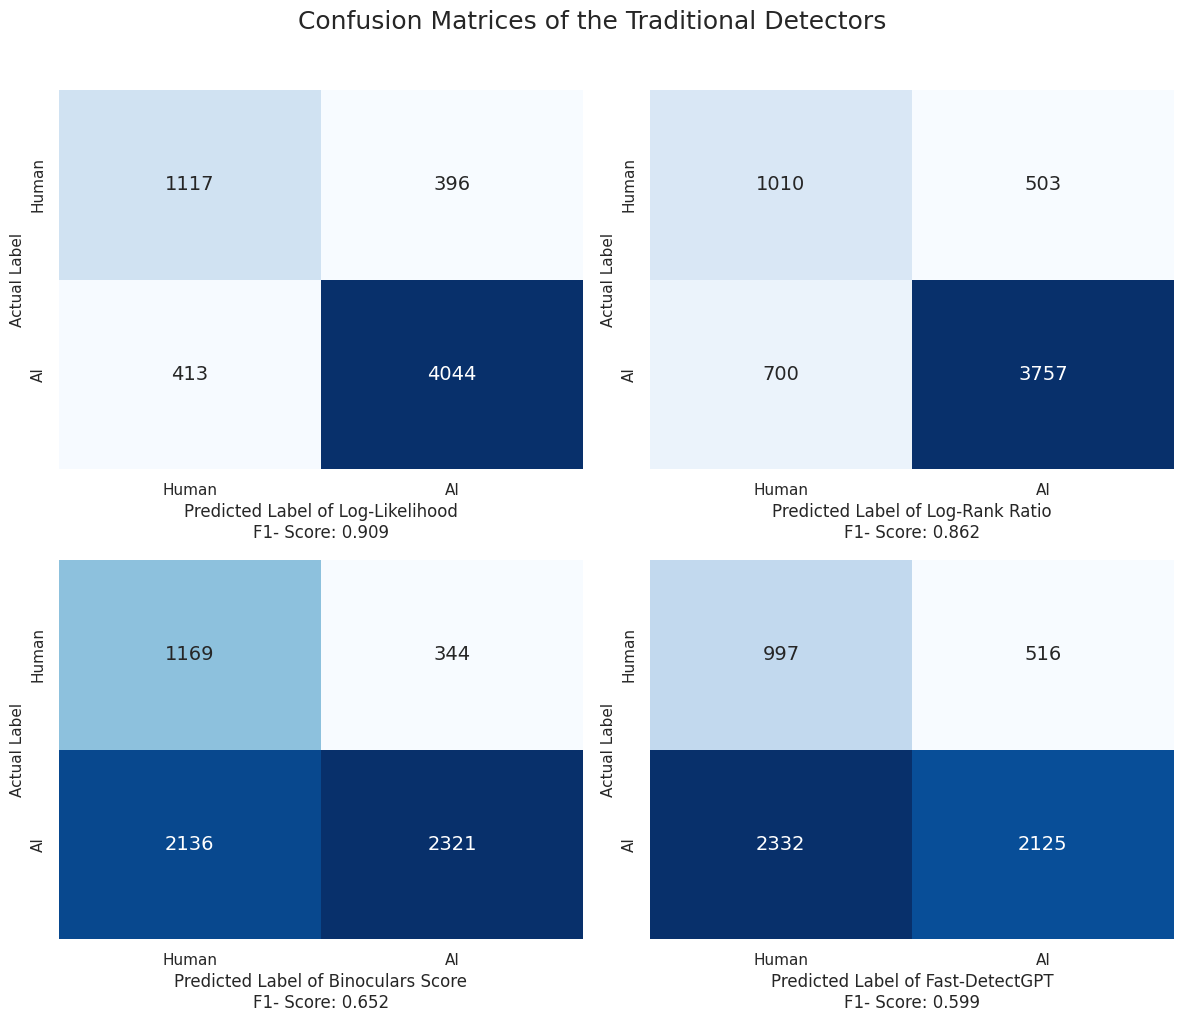

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import f1_score, confusion_matrix, roc_curve, roc_auc_score

# 1. Load your completed results
DRIVE_DIR = "/content/drive/MyDrive/Detection_thesis"
csv_path = os.path.join(DRIVE_DIR, "detector_scores.csv")
df = pd.read_csv(csv_path).dropna()

y_true = df['label'].values  # 0: Human, 1: AI

# List of metrics to evaluate
metrics = {
    'score_log_likelihood': 'Log-Likelihood',
    'score_lrr': 'Log-Rank Ratio',
    'score_binoculars': 'Binoculars Score',
    'score_fast_detect': 'Fast-DetectGPT'
}

# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
sns.set_theme(style="white")

print("🏆 TRUE BALANCED THRESHOLDS (Auto-Corrected) 🏆")
print("-" * 50)

for idx, (col, name) in enumerate(metrics.items()):
    y_scores = df[col].values

    # --- THE FOOLPROOF FIX ---
    # 1. Check the raw AUC first to see what the data is actually doing
    raw_auc = roc_auc_score(y_true, y_scores)

    # 2. If AUC < 0.5, Human scores are higher than AI scores.
    # We MUST mathematically invert them in memory so Youden's J works.
    if raw_auc < 0.5:
        y_scores = -y_scores
        actual_auc = 1.0 - raw_auc
        inverted = True
    else:
        actual_auc = raw_auc
        inverted = False

    fpr, tpr, thresholds = roc_curve(y_true, y_scores)

    # 3. Calculate Youden's J on the properly oriented scores
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    best_thresh = thresholds[best_idx]

    # Generate balanced predictions
    best_preds = (y_scores >= best_thresh).astype(int)
    realistic_f1 = f1_score(y_true, best_preds)

    # Print the clean results
    display_thresh = -best_thresh if inverted else best_thresh
    print(f"{name}:")
    print(f"  -> True AUC: {actual_auc:.3f} (Inverted: {inverted})")
    print(f"  -> Realistic F1 Score: {realistic_f1:.3f}")
    print(f"  -> Optimal Threshold: {display_thresh:.3f}\n")

    # Create the Confusion Matrix
    cm = confusion_matrix(y_true, best_preds)

    # Plot it beautifully
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
        xticklabels=['Human', 'AI'],
        yticklabels=['Human', 'AI'],
        cbar=False, annot_kws={"size": 14}
    )

    # Modifying the labels to act as a footer instead of a title
    axes[idx].set_xlabel(f'Predicted Label of {name}\nF1- Score: {realistic_f1:.3f}', fontsize=12)
    axes[idx].set_ylabel('Actual Label', fontsize=11)
    # Removing the title since it's now in the xlabel footer
    axes[idx].set_title("", fontsize=14, pad=10)

plt.suptitle("Confusion Matrices of the Traditional Detectors", fontsize=18, y=1.02)
plt.tight_layout()

cm_save_path = os.path.join(DRIVE_DIR, "confusion_matrices_final.png")
plt.savefig(cm_save_path, dpi=300, bbox_inches='tight')
plt.show()
